# Lecture 4: Linear Algebra for Dimensionality Reduction

**Duration:** 2.5–3 hours  
**Topics:**
- Matrix representation of data
- Matrix multiplication
- Dot product & projections
- Eigenvalues & eigenvectors
- Variance maximization
- Matrix determinant (volume intuition)

---

## Introduction

In previous lectures, we've explored:
- **Lecture 1:** How data exists as points in n-dimensional space, and how variance captures information
- **Lecture 2:** How vectors represent data, and how we measure distances and angles between them
- **Lecture 3:** How probability distributions describe data, and how covariance matrices capture relationships

Today, we'll tie these concepts together through **linear algebra**—the mathematical framework that makes machine learning possible. We'll see how matrices naturally represent datasets, how matrix operations transform data, and most importantly, how these operations enable **dimensionality reduction**.

By the end of this lecture, you'll understand the mathematical foundations of Principal Component Analysis (PCA), one of the most important techniques in machine learning for:
- Reducing computational complexity
- Visualizing high-dimensional data
- Removing noise
- Finding the most informative directions in data

In [ ]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d import proj3d

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
np.random.seed(42)

---

## 1. Matrix Representation of Data

### Why Matrices?

Recall from Lecture 1 that we think of data as **points in n-dimensional space**. A matrix is the natural way to organize this data:

- Each **row** represents one data point (sample)
- Each **column** represents one feature (dimension)

$$
\mathbf{X} = \begin{bmatrix}
x_{1,1} & x_{1,2} & \cdots & x_{1,p} \\
x_{2,1} & x_{2,2} & \cdots & x_{2,p} \\
\vdots & \vdots & \ddots & \vdots \\
x_{n,1} & x_{n,2} & \cdots & x_{n,p}
\end{bmatrix}
$$

This is an $n \times p$ matrix where:
- $n$ = number of samples
- $p$ = number of features

### Geometric Interpretation

Think of the matrix as a **collection of vectors**:
- **Row vectors:** Each row is a point in $p$-dimensional space
- **Column vectors:** Each column shows how all samples vary along one feature

In [ ]:
# Create a simple dataset: student test scores
# Features: Math score, Physics score, Chemistry score
data = np.array([
    [85, 78, 82],  # Student 1
    [92, 88, 90],  # Student 2
    [78, 72, 75],  # Student 3
    [95, 91, 93],  # Student 4
    [88, 85, 87]   # Student 5
])

print("Data Matrix (5 students × 3 subjects):")
print(data)
print(f"\nShape: {data.shape}")
print(f"Number of students (samples): {data.shape[0]}")
print(f"Number of subjects (features): {data.shape[1]}")

Data Matrix (5 students × 3 subjects):
[[85 78 82]
 [92 88 90]
 [78 72 75]
 [95 91 93]
 [88 85 87]]

Shape: (5, 3)
Number of students (samples): 5
Number of subjects (features): 3


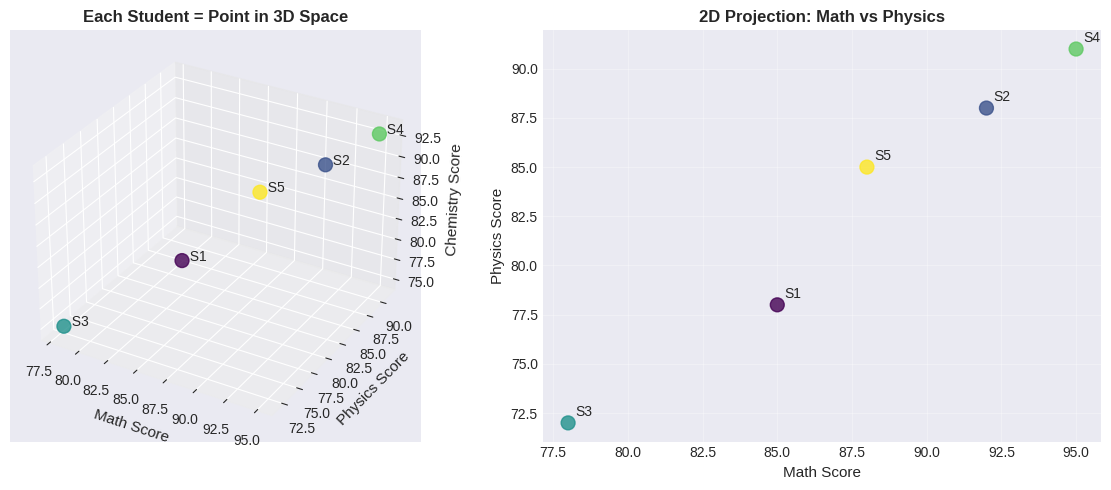


💡 Key Insight: Each student is a point. Each dimension is a feature.
   The matrix is just an organized way to store these coordinates!


In [ ]:
# Visualize data points in 3D space
fig = plt.figure(figsize=(12, 5))

# 3D scatter plot
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(data[:, 0], data[:, 1], data[:, 2],
           c=range(len(data)), cmap='viridis', s=100, alpha=0.8)

for i, (x, y, z) in enumerate(data):
    ax1.text(x, y, z, f'  S{i+1}', fontsize=10)

ax1.set_xlabel('Math Score', fontsize=11)
ax1.set_ylabel('Physics Score', fontsize=11)
ax1.set_zlabel('Chemistry Score', fontsize=11)
ax1.set_title('Each Student = Point in 3D Space', fontsize=12, fontweight='bold')

# 2D projection (Math vs Physics)
ax2 = fig.add_subplot(122)
ax2.scatter(data[:, 0], data[:, 1], c=range(len(data)),
           cmap='viridis', s=100, alpha=0.8)

for i, (x, y) in enumerate(data[:, :2]):
    ax2.annotate(f'S{i+1}', (x, y), xytext=(5, 5),
                textcoords='offset points', fontsize=10)

ax2.set_xlabel('Math Score', fontsize=11)
ax2.set_ylabel('Physics Score', fontsize=11)
ax2.set_title('2D Projection: Math vs Physics', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 Key Insight: Each student is a point. Each dimension is a feature.")
print("   The matrix is just an organized way to store these coordinates!")

### Centering Data: Connection to Lecture 1

Remember **mean** from Lecture 1? Centering data (subtracting the mean) is crucial for dimensionality reduction:

$$\mathbf{X}_{\text{centered}} = \mathbf{X} - \mathbf{\bar{x}}$$

where $\mathbf{\bar{x}}$ is the mean of each column (feature).

**Why center?** It shifts the origin to the center of the data cloud, making it easier to find principal directions.

In [ ]:
# Center the data
mean_scores = data.mean(axis=0)
data_centered = data - mean_scores

print("Original mean (per subject):")
print(mean_scores)
print("\nCentered data:")
print(data_centered)
print("\nNew mean (should be ~0):")
print(data_centered.mean(axis=0))

Original mean (per subject):
[87.6 82.8 85.4]

Centered data:
[[ -2.6  -4.8  -3.4]
 [  4.4   5.2   4.6]
 [ -9.6 -10.8 -10.4]
 [  7.4   8.2   7.6]
 [  0.4   2.2   1.6]]

New mean (should be ~0):
[ 5.68434189e-15  2.84217094e-15 -5.68434189e-15]


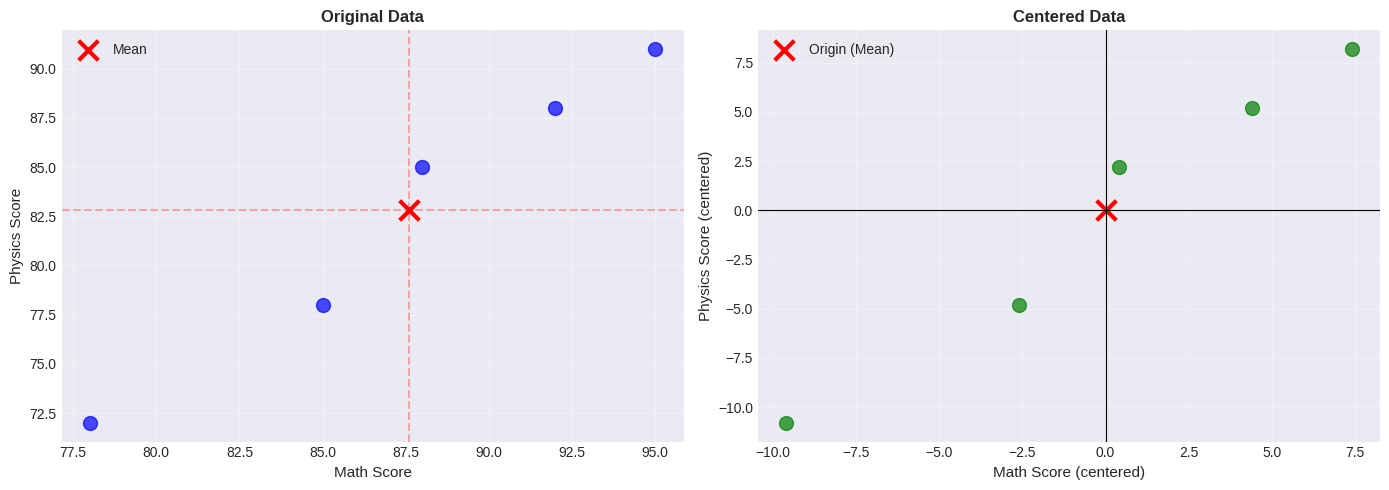


💡 Centering moves the origin to the data's center.
   This is essential for finding directions of maximum variance!


In [ ]:
# Visualize centered vs uncentered data
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original data
axes[0].scatter(data[:, 0], data[:, 1], s=100, alpha=0.7, c='blue')
axes[0].scatter(mean_scores[0], mean_scores[1], s=200, c='red',
               marker='x', linewidths=3, label='Mean')
axes[0].axhline(y=mean_scores[1], color='red', linestyle='--', alpha=0.3)
axes[0].axvline(x=mean_scores[0], color='red', linestyle='--', alpha=0.3)
axes[0].set_xlabel('Math Score', fontsize=11)
axes[0].set_ylabel('Physics Score', fontsize=11)
axes[0].set_title('Original Data', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Centered data
axes[1].scatter(data_centered[:, 0], data_centered[:, 1], s=100, alpha=0.7, c='green')
axes[1].scatter(0, 0, s=200, c='red', marker='x', linewidths=3, label='Origin (Mean)')
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.8)
axes[1].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
axes[1].set_xlabel('Math Score (centered)', fontsize=11)
axes[1].set_ylabel('Physics Score (centered)', fontsize=11)
axes[1].set_title('Centered Data', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 Centering moves the origin to the data's center.")
print("   This is essential for finding directions of maximum variance!")

### Real-World Dataset Example

In [ ]:
# Generate a realistic dataset: house prices
np.random.seed(42)
n_houses = 100

square_feet = np.random.normal(2000, 500, n_houses)
num_bedrooms = np.random.poisson(3, n_houses)
age_years = np.random.uniform(0, 50, n_houses)
price = 100000 + 150 * square_feet + 20000 * num_bedrooms - 1000 * age_years + np.random.normal(0, 30000, n_houses)

# Create matrix
house_data = np.column_stack([square_feet, num_bedrooms, age_years, price])

# Display as DataFrame for clarity
df = pd.DataFrame(house_data,
                 columns=['Square Feet', 'Bedrooms', 'Age (years)', 'Price ($)'])
print("House Price Dataset (first 10 rows):")
print(df.head(10))
print(f"\nMatrix shape: {house_data.shape} (100 houses × 4 features)")

House Price Dataset (first 10 rows):
   Square Feet  Bedrooms  Age (years)      Price ($)
0  2248.357077       2.0     6.457971  465188.437041
1  1930.867849       4.0    47.702551  420493.899728
2  2323.844269       4.0    30.308732  466430.029647
3  2761.514928       2.0    11.432140  523163.898572
4  1882.923313       2.0    33.585034  365656.713562
5  1882.931522       3.0    30.906412  401009.638851
6  2789.606408       5.0    17.908136  607079.507237
7  2383.717365       5.0     5.677880  579196.648748
8  1765.262807       3.0    33.578660  422870.691172
9  2271.280022       2.0    26.015385  474285.646064

Matrix shape: (100, 4) (100 houses × 4 features)


**Key Takeaway:** Matrices are the natural data structure for ML. Every row is a sample, every column is a feature. This organization enables efficient computation and mathematical operations.

---

## 2. Matrix Multiplication: Geometric Interpretation

### What Does Matrix Multiplication Do?

Matrix multiplication isn't just arithmetic—it's a **geometric transformation**. When we multiply a matrix by a vector, we're:
1. Rotating the vector
2. Stretching/shrinking it
3. Possibly changing dimensions

**Formal definition:** For matrices $\mathbf{A}$ (size $m \times n$) and $\mathbf{B}$ (size $n \times p$):

$$
(\mathbf{AB})_{ij} = \sum_{k=1}^{n} a_{ik} \cdot b_{kj}
$$

**Intuitive understanding:** Each element in the result is a **dot product** (from Lecture 2!) of a row from $\mathbf{A}$ and a column from $\mathbf{B}$.

In [ ]:
# Simple example: rotating a 2D vector
# Rotation matrix for 45 degrees counterclockwise
theta = np.pi / 4  # 45 degrees
rotation_matrix = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])

# Original vector
v = np.array([3, 1])

# Apply rotation
v_rotated = rotation_matrix @ v  # @ is matrix multiplication in NumPy

print("Original vector:", v)
print("Rotation matrix (45°):")
print(rotation_matrix)
print("Rotated vector:", v_rotated)

Original vector: [3 1]
Rotation matrix (45°):
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]
Rotated vector: [1.41421356 2.82842712]


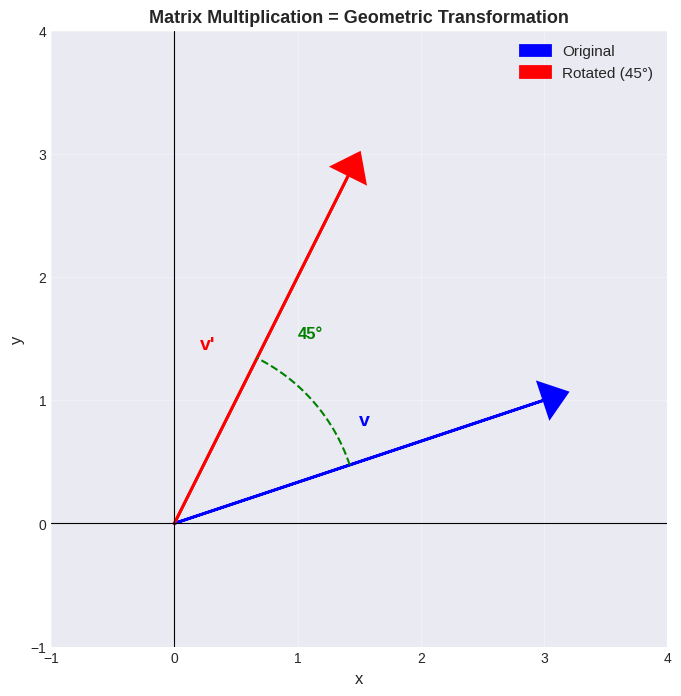


💡 Matrix multiplication transforms vectors geometrically!


In [ ]:
# Visualize the rotation
fig, ax = plt.subplots(figsize=(8, 8))

# Plot original vector
ax.arrow(0, 0, v[0], v[1], head_width=0.3, head_length=0.2,
         fc='blue', ec='blue', linewidth=2, label='Original')
ax.text(v[0]/2, v[1]/2 + 0.3, 'v', fontsize=14, color='blue', fontweight='bold')

# Plot rotated vector
ax.arrow(0, 0, v_rotated[0], v_rotated[1], head_width=0.3, head_length=0.2,
         fc='red', ec='red', linewidth=2, label='Rotated (45°)')
ax.text(v_rotated[0]/2 - 0.5, v_rotated[1]/2, "v'", fontsize=14,
        color='red', fontweight='bold')

# Plot arc showing rotation angle
angle_arc = np.linspace(np.arctan2(v[1], v[0]),
                       np.arctan2(v_rotated[1], v_rotated[0]), 30)
ax.plot(1.5*np.cos(angle_arc), 1.5*np.sin(angle_arc), 'g--', linewidth=1.5)
ax.text(1, 1.5, '45°', fontsize=12, color='green', fontweight='bold')

ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linewidth=0.8)
ax.axvline(x=0, color='k', linewidth=0.8)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)
ax.set_title('Matrix Multiplication = Geometric Transformation',
            fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.show()

print("\n💡 Matrix multiplication transforms vectors geometrically!")

### Transforming Entire Datasets

When we multiply a data matrix by a transformation matrix, we apply the transformation to **every data point** simultaneously:

$$\mathbf{X}_{\text{transformed}} = \mathbf{X} \mathbf{W}$$

This is exactly what happens in dimensionality reduction!

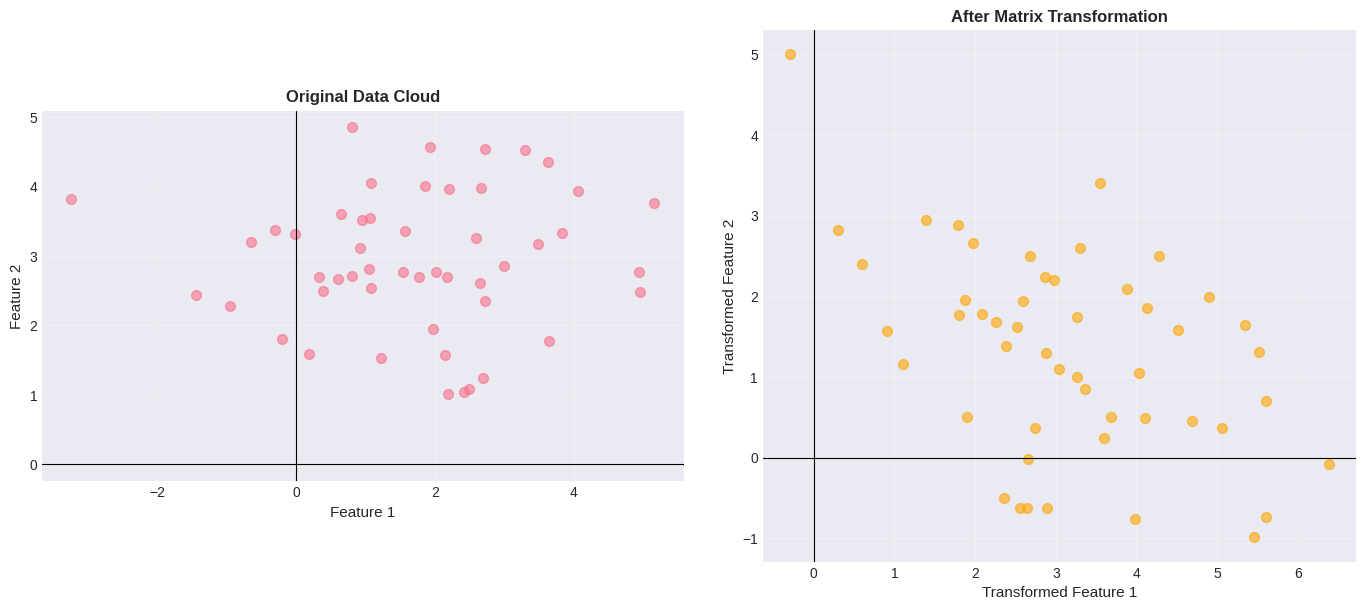


💡 Matrix multiplication transforms ALL points simultaneously.
   This is the foundation of dimensionality reduction!


In [ ]:
# Generate random 2D data points
np.random.seed(42)
n_points = 50
data_points = np.random.randn(n_points, 2) * [2, 1] + [2, 3]

# Transformation matrix (rotation + scaling)
transform = np.array([[0.8, 0.6], [-0.6, 0.8]])  # Rotation + scale

# Apply transformation
transformed_points = data_points @ transform.T

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Original data
axes[0].scatter(data_points[:, 0], data_points[:, 1], alpha=0.6, s=50)
axes[0].set_title('Original Data Cloud', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Feature 1', fontsize=11)
axes[0].set_ylabel('Feature 2', fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=0, color='k', linewidth=0.8)
axes[0].axvline(x=0, color='k', linewidth=0.8)
axes[0].set_aspect('equal')

# Transformed data
axes[1].scatter(transformed_points[:, 0], transformed_points[:, 1],
               alpha=0.6, s=50, c='orange')
axes[1].set_title('After Matrix Transformation', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Transformed Feature 1', fontsize=11)
axes[1].set_ylabel('Transformed Feature 2', fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=0, color='k', linewidth=0.8)
axes[1].axvline(x=0, color='k', linewidth=0.8)
axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()

print("\n💡 Matrix multiplication transforms ALL points simultaneously.")
print("   This is the foundation of dimensionality reduction!")

### Matrix Multiplication Properties

Important properties:
1. **Not commutative:** $\mathbf{AB} \neq \mathbf{BA}$ (order matters!)
2. **Associative:** $(\mathbf{AB})\mathbf{C} = \mathbf{A}(\mathbf{BC})$
3. **Distributive:** $\mathbf{A}(\mathbf{B} + \mathbf{C}) = \mathbf{AB} + \mathbf{AC}$
4. **Dimension rule:** $(m \times n) \times (n \times p) = (m \times p)$

In [ ]:
# Demonstrate non-commutativity
A = np.array([[1, 2], [3, 4]])
B = np.array([[0, 1], [1, 0]])

AB = A @ B
BA = B @ A

print("Matrix A:")
print(A)
print("\nMatrix B:")
print(B)
print("\nA × B:")
print(AB)
print("\nB × A:")
print(BA)
print("\nAre they equal?", np.array_equal(AB, BA))
print("\n⚠️  Order matters in matrix multiplication!")

Matrix A:
[[1 2]
 [3 4]]

Matrix B:
[[0 1]
 [1 0]]

A × B:
[[2 1]
 [4 3]]

B × A:
[[3 4]
 [1 2]]

Are they equal? False

⚠️  Order matters in matrix multiplication!


---

## 3. Dot Product & Projections

### Review: Dot Product (from Lecture 2)

The **dot product** measures how much two vectors align:

$$\mathbf{a} \cdot \mathbf{b} = \sum_{i=1}^{n} a_i b_i = \|\mathbf{a}\| \|\mathbf{b}\| \cos(\theta)$$

where $\theta$ is the angle between vectors.

**Geometric meaning:**
- Positive: vectors point in similar directions
- Zero: vectors are perpendicular (orthogonal)
- Negative: vectors point in opposite directions

/tmp/ipython-input-1046894509.py:31: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipython-input-1046894509.py:31: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


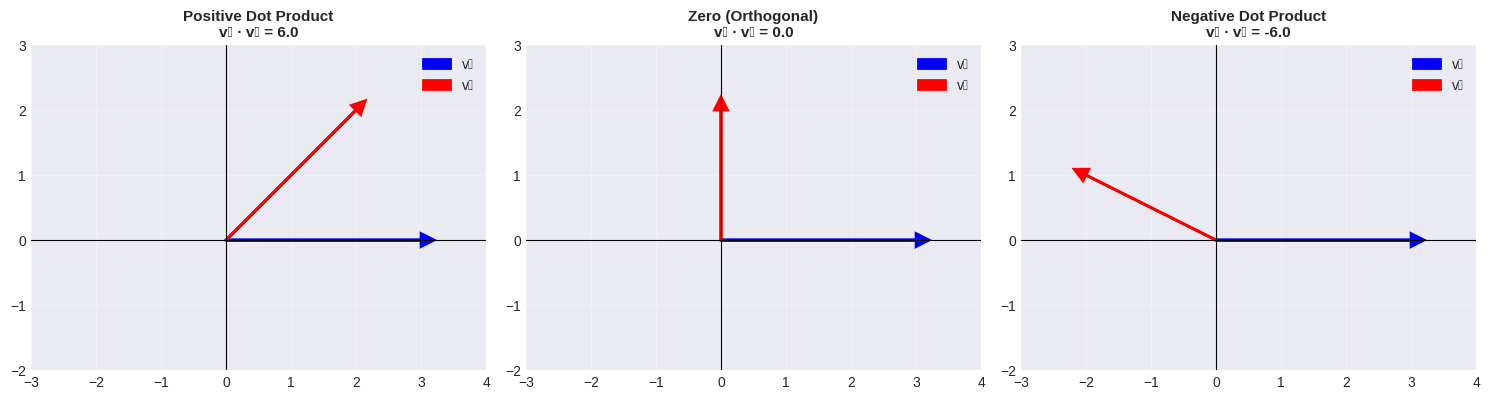

In [ ]:
# Visualize dot product for different angles
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

v1 = np.array([3, 0])
vectors = [
    (np.array([2, 2]), "Positive Dot Product", 0),
    (np.array([0, 2]), "Zero (Orthogonal)", 1),
    (np.array([-2, 1]), "Negative Dot Product", 2)
]

for v2, title, idx in vectors:
    ax = axes[idx]
    dot_prod = np.dot(v1, v2)

    # Plot vectors
    ax.arrow(0, 0, v1[0], v1[1], head_width=0.2, head_length=0.2,
            fc='blue', ec='blue', linewidth=2, label='v₁')
    ax.arrow(0, 0, v2[0], v2[1], head_width=0.2, head_length=0.2,
            fc='red', ec='red', linewidth=2, label='v₂')

    ax.set_xlim(-3, 4)
    ax.set_ylim(-2, 3)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='k', linewidth=0.8)
    ax.axvline(x=0, color='k', linewidth=0.8)
    ax.set_title(f"{title}\nv₁ · v₂ = {dot_prod:.1f}",
                fontsize=11, fontweight='bold')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### Projection: The Heart of Dimensionality Reduction

**Projection** is the shadow of one vector onto another. It answers: *"How much of vector $\mathbf{a}$ lies in the direction of vector $\mathbf{b}$?"*

**Scalar projection** (length of shadow):
$$\text{comp}_{\mathbf{b}} \mathbf{a} = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{b}\|}$$

**Vector projection** (actual shadow vector):
$$\text{proj}_{\mathbf{b}} \mathbf{a} = \frac{\mathbf{a} \cdot \mathbf{b}}{\mathbf{b} \cdot \mathbf{b}} \mathbf{b}$$

**This is crucial:** When we reduce dimensions, we're projecting high-dimensional data onto lower-dimensional subspaces!

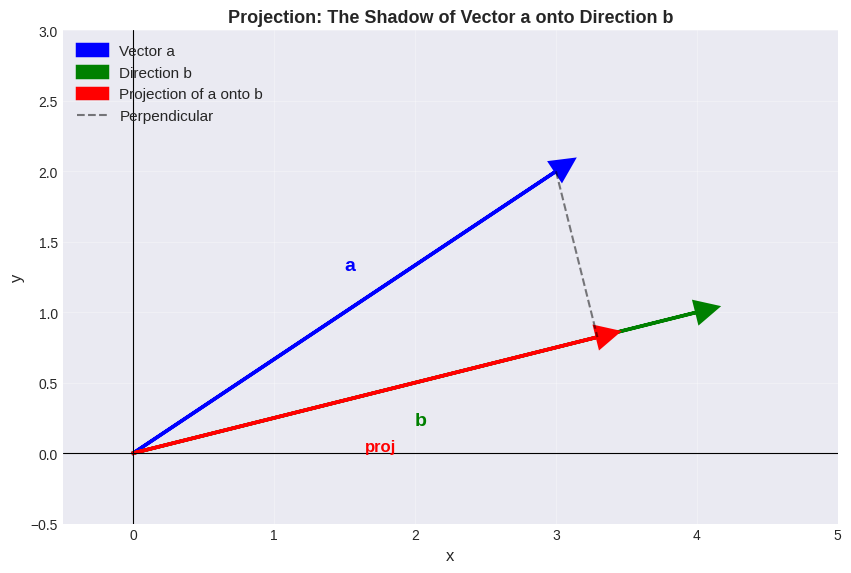

Vector a: [3 2]
Direction b: [4 1]
Projection of a onto b: [3.29411765 0.82352941]

Scalar projection (length): 3.40

💡 Projection = how much of 'a' points in direction 'b'


In [ ]:
# Visualize projection
a = np.array([3, 2])
b = np.array([4, 1])

# Calculate projection
proj_a_onto_b = (np.dot(a, b) / np.dot(b, b)) * b

fig, ax = plt.subplots(figsize=(10, 8))

# Plot vectors
ax.arrow(0, 0, a[0], a[1], head_width=0.15, head_length=0.15,
        fc='blue', ec='blue', linewidth=2.5, label='Vector a')
ax.arrow(0, 0, b[0], b[1], head_width=0.15, head_length=0.15,
        fc='green', ec='green', linewidth=2.5, label='Direction b')
ax.arrow(0, 0, proj_a_onto_b[0], proj_a_onto_b[1],
        head_width=0.15, head_length=0.15,
        fc='red', ec='red', linewidth=2.5, label='Projection of a onto b')

# Draw perpendicular line from a to projection
ax.plot([a[0], proj_a_onto_b[0]], [a[1], proj_a_onto_b[1]],
       'k--', linewidth=1.5, alpha=0.5, label='Perpendicular')

# Add labels
ax.text(a[0]/2, a[1]/2 + 0.3, 'a', fontsize=14, color='blue', fontweight='bold')
ax.text(b[0]/2, b[1]/2 - 0.3, 'b', fontsize=14, color='green', fontweight='bold')
ax.text(proj_a_onto_b[0]/2, proj_a_onto_b[1]/2 - 0.4, 'proj',
       fontsize=12, color='red', fontweight='bold')

ax.set_xlim(-0.5, 5)
ax.set_ylim(-0.5, 3)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linewidth=0.8)
ax.axvline(x=0, color='k', linewidth=0.8)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)
ax.set_title('Projection: The Shadow of Vector a onto Direction b',
            fontsize=13, fontweight='bold')
ax.legend(fontsize=11, loc='upper left')
plt.show()

print(f"Vector a: {a}")
print(f"Direction b: {b}")
print(f"Projection of a onto b: {proj_a_onto_b}")
print(f"\nScalar projection (length): {np.dot(a, b) / np.linalg.norm(b):.2f}")
print("\n💡 Projection = how much of 'a' points in direction 'b'")

### Projection in Higher Dimensions

The same concept works in any dimension. This is how we reduce a 1000-dimensional dataset to 2D for visualization!

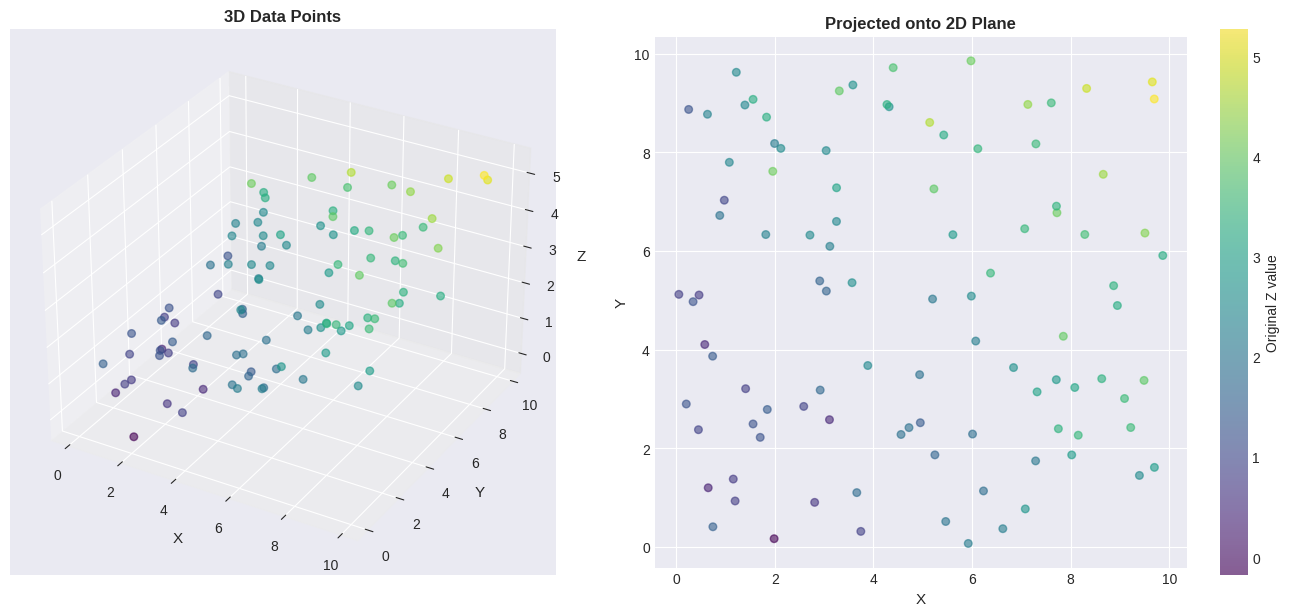


💡 Dimensionality reduction = projecting onto lower-dimensional subspaces!


In [ ]:
# 3D projection example
# Project 3D data onto a 2D plane
np.random.seed(42)

# Create 3D points on a tilted plane
n_points = 100
t = np.random.rand(n_points) * 10
s = np.random.rand(n_points) * 10

# Points on plane: z = 0.3x + 0.2y
x = t
y = s
z = 0.3 * x + 0.2 * y + np.random.randn(n_points) * 0.5

points_3d = np.column_stack([x, y, z])

# Define a 2D plane (normal vector)
# We'll project onto the xy-plane for simplicity
projected_2d = points_3d[:, :2]  # Just take x and y

fig = plt.figure(figsize=(14, 6))

# 3D view
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(x, y, z, c=z, cmap='viridis', s=30, alpha=0.6)
ax1.set_xlabel('X', fontsize=11)
ax1.set_ylabel('Y', fontsize=11)
ax1.set_zlabel('Z', fontsize=11)
ax1.set_title('3D Data Points', fontsize=12, fontweight='bold')

# 2D projection
ax2 = fig.add_subplot(122)
scatter = ax2.scatter(projected_2d[:, 0], projected_2d[:, 1],
                     c=z, cmap='viridis', s=30, alpha=0.6)
ax2.set_xlabel('X', fontsize=11)
ax2.set_ylabel('Y', fontsize=11)
ax2.set_title('Projected onto 2D Plane', fontsize=12, fontweight='bold')
ax2.set_aspect('equal')
plt.colorbar(scatter, ax=ax2, label='Original Z value')

plt.tight_layout()
plt.show()

print("\n💡 Dimensionality reduction = projecting onto lower-dimensional subspaces!")

**Key Insight:** Projection loses information (the perpendicular component), but if we choose the right direction, we can keep the most important information while reducing dimensions.

---

## 4. Eigenvalues & Eigenvectors: The Magic of Linear Algebra

### What Are Eigenvectors?

An **eigenvector** of a matrix $\mathbf{A}$ is a special vector that doesn't change direction when $\mathbf{A}$ is applied to it—it only gets scaled:

$$\mathbf{A}\mathbf{v} = \lambda \mathbf{v}$$

where:
- $\mathbf{v}$ is the eigenvector (direction that stays the same)
- $\lambda$ is the eigenvalue (how much it gets scaled)

**Intuition:** Eigenvectors are the "natural axes" of a transformation. They show the fundamental directions in which the matrix acts.

In [ ]:
# Simple example
A = np.array([[3, 1],
              [1, 3]])

# Compute eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(A)

print("Matrix A:")
print(A)
print("\nEigenvalues (λ):")
print(eigenvalues)
print("\nEigenvectors (v):")
print(eigenvectors)

# Verify the equation Av = λv for first eigenvector
v1 = eigenvectors[:, 0]
lambda1 = eigenvalues[0]

Av1 = A @ v1
lambda_v1 = lambda1 * v1

print("\n--- Verification for first eigenvector ---")
print(f"A × v₁ = {Av1}")
print(f"λ₁ × v₁ = {lambda_v1}")
print(f"Are they equal? {np.allclose(Av1, lambda_v1)}")

Matrix A:
[[3 1]
 [1 3]]

Eigenvalues (λ):
[4. 2.]

Eigenvectors (v):
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]

--- Verification for first eigenvector ---
A × v₁ = [2.82842712 2.82842712]
λ₁ × v₁ = [2.82842712 2.82842712]
Are they equal? True


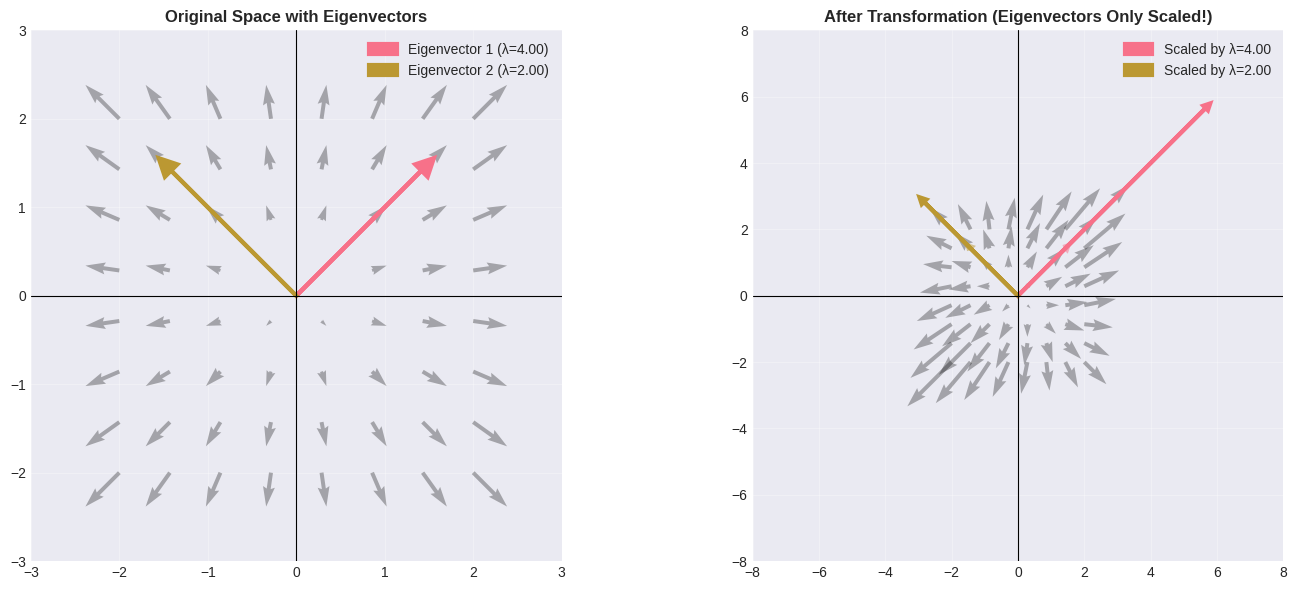


💡 Eigenvectors don't change direction—they only get scaled!
   They reveal the fundamental directions of the transformation.


In [ ]:
# Visualize eigenvectors
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Create a grid of vectors
x = np.linspace(-2, 2, 8)
y = np.linspace(-2, 2, 8)
X, Y = np.meshgrid(x, y)

# Original vectors
ax1 = axes[0]
ax1.quiver(X, Y, X, Y, alpha=0.3)

# Plot eigenvectors
for i in range(2):
    ev = eigenvectors[:, i] * 2
    ax1.arrow(0, 0, ev[0], ev[1], head_width=0.2, head_length=0.2,
             fc=f'C{i}', ec=f'C{i}', linewidth=3,
             label=f'Eigenvector {i+1} (λ={eigenvalues[i]:.2f})')

ax1.set_xlim(-3, 3)
ax1.set_ylim(-3, 3)
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.3)
ax1.axhline(y=0, color='k', linewidth=0.8)
ax1.axvline(x=0, color='k', linewidth=0.8)
ax1.set_title('Original Space with Eigenvectors', fontsize=12, fontweight='bold')
ax1.legend()

# Transformed vectors
ax2 = axes[1]

# Apply transformation to grid
vectors = np.column_stack([X.ravel(), Y.ravel()])
transformed = (A @ vectors.T).T
U = transformed[:, 0].reshape(X.shape)
V = transformed[:, 1].reshape(Y.shape)

ax2.quiver(X, Y, U, V, alpha=0.3)

# Plot transformed eigenvectors
for i in range(2):
    ev_original = eigenvectors[:, i] * 2
    ev_transformed = A @ ev_original

    # Original eigenvector (dashed)
    ax2.arrow(0, 0, ev_original[0], ev_original[1],
             head_width=0.2, head_length=0.2,
             fc='none', ec=f'C{i}', linewidth=2, linestyle='--', alpha=0.5)

    # Transformed eigenvector (solid)
    ax2.arrow(0, 0, ev_transformed[0], ev_transformed[1],
             head_width=0.2, head_length=0.2,
             fc=f'C{i}', ec=f'C{i}', linewidth=3,
             label=f'Scaled by λ={eigenvalues[i]:.2f}')

ax2.set_xlim(-8, 8)
ax2.set_ylim(-8, 8)
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)
ax2.axhline(y=0, color='k', linewidth=0.8)
ax2.axvline(x=0, color='k', linewidth=0.8)
ax2.set_title('After Transformation (Eigenvectors Only Scaled!)',
             fontsize=12, fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()

print("\n💡 Eigenvectors don't change direction—they only get scaled!")
print("   They reveal the fundamental directions of the transformation.")

### Connection to Covariance (Lecture 3)

Remember the **covariance matrix** from Lecture 3? Its eigenvectors are incredibly important:

The eigenvectors of the covariance matrix point in the directions of **maximum variance** in the data!

$$\mathbf{C} = \frac{1}{n-1} \mathbf{X}^T \mathbf{X}$$

- The eigenvector with the **largest eigenvalue** points in the direction of greatest variance
- The eigenvector with the **second-largest eigenvalue** points in the direction of second-greatest variance
- And so on...

**This is the foundation of PCA!**

In [ ]:
# Generate correlated 2D data
np.random.seed(42)
mean = [0, 0]
cov = [[3, 1.5],   # Covariance matrix
       [1.5, 1]]
data_2d = np.random.multivariate_normal(mean, cov, 500)

# Center the data
data_centered = data_2d - data_2d.mean(axis=0)

# Compute covariance matrix
cov_matrix = np.cov(data_centered.T)

# Get eigenvectors and eigenvalues
eigenvalues_cov, eigenvectors_cov = np.linalg.eig(cov_matrix)

# Sort by eigenvalue (largest first)
idx = eigenvalues_cov.argsort()[::-1]
eigenvalues_cov = eigenvalues_cov[idx]
eigenvectors_cov = eigenvectors_cov[:, idx]

print("Covariance Matrix:")
print(cov_matrix)
print("\nEigenvalues (variances along principal directions):")
print(eigenvalues_cov)
print("\nEigenvectors (principal directions):")
print(eigenvectors_cov)

Covariance Matrix:
[[2.7893851  1.4108776 ]
 [1.4108776  0.96087091]]

Eigenvalues (variances along principal directions):
[3.55633044 0.19392557]

Eigenvectors (principal directions):
[[ 0.87858165 -0.47759218]
 [ 0.47759218  0.87858165]]


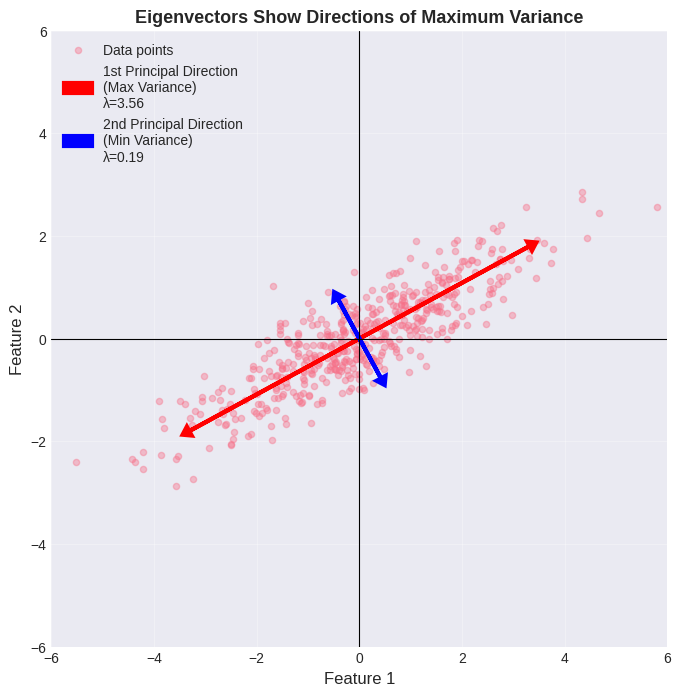


💡 The eigenvector with the largest eigenvalue points where data varies most!
   This is the direction we'd keep if reducing to 1D.


In [ ]:
# Visualize data with eigenvectors
fig, ax = plt.subplots(figsize=(10, 8))

# Plot data
ax.scatter(data_centered[:, 0], data_centered[:, 1],
          alpha=0.4, s=20, label='Data points')

# Plot eigenvectors (scaled by sqrt of eigenvalue)
origin = np.array([0, 0])
colors = ['red', 'blue']
labels = ['1st Principal Direction\n(Max Variance)',
         '2nd Principal Direction\n(Min Variance)']

for i in range(2):
    # Scale eigenvector by square root of eigenvalue (std dev)
    ev = eigenvectors_cov[:, i] * np.sqrt(eigenvalues_cov[i]) * 2
    ax.arrow(0, 0, ev[0], ev[1], head_width=0.2, head_length=0.15,
            fc=colors[i], ec=colors[i], linewidth=3,
            label=f'{labels[i]}\nλ={eigenvalues_cov[i]:.2f}')
    ax.arrow(0, 0, -ev[0], -ev[1], head_width=0.2, head_length=0.15,
            fc=colors[i], ec=colors[i], linewidth=3)

ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linewidth=0.8)
ax.axvline(x=0, color='k', linewidth=0.8)
ax.set_xlabel('Feature 1', fontsize=12)
ax.set_ylabel('Feature 2', fontsize=12)
ax.set_title('Eigenvectors Show Directions of Maximum Variance',
            fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper left')
plt.show()

print("\n💡 The eigenvector with the largest eigenvalue points where data varies most!")
print("   This is the direction we'd keep if reducing to 1D.")

---

## 5. Variance Maximization: The Goal of PCA

### Why Maximize Variance?

Recall from Lecture 1: **variance measures information content**.

When reducing dimensions, we want to:
1. **Keep as much information as possible**
2. **Remove redundancy and noise**

The solution: **Find directions that capture the most variance!**

### Variance Along a Direction

Given a unit vector $\mathbf{u}$ (direction) and centered data $\mathbf{X}$:

The variance of data projected onto $\mathbf{u}$ is:
$$\text{Var}(\mathbf{X}\mathbf{u}) = \mathbf{u}^T \mathbf{C} \mathbf{u}$$

where $\mathbf{C}$ is the covariance matrix.

**The magic:** Maximizing this variance leads us directly to eigenvectors!

In [ ]:
# Calculate variance along different directions
def variance_along_direction(data, direction):
    """Calculate variance of data projected onto a direction."""
    # Normalize direction
    direction = direction / np.linalg.norm(direction)
    # Project data
    projected = data @ direction
    # Return variance
    return np.var(projected)

# Test different angles
angles = np.linspace(0, 2*np.pi, 100)
variances = []

for angle in angles:
    direction = np.array([np.cos(angle), np.sin(angle)])
    var = variance_along_direction(data_centered, direction)
    variances.append(var)

variances = np.array(variances)

# Find angles of maximum and minimum variance
max_idx = np.argmax(variances)
min_idx = np.argmin(variances)

max_angle = angles[max_idx]
min_angle = angles[min_idx]

print(f"Maximum variance: {variances[max_idx]:.4f} at angle {np.degrees(max_angle):.1f}°")
print(f"Minimum variance: {variances[min_idx]:.4f} at angle {np.degrees(min_angle):.1f}°")
print(f"\nFirst eigenvalue (max variance): {eigenvalues_cov[0]:.4f}")
print(f"Second eigenvalue (min variance): {eigenvalues_cov[1]:.4f}")

Maximum variance: 3.5489 at angle 29.1°
Minimum variance: 0.1937 at angle 298.2°

First eigenvalue (max variance): 3.5563
Second eigenvalue (min variance): 0.1939


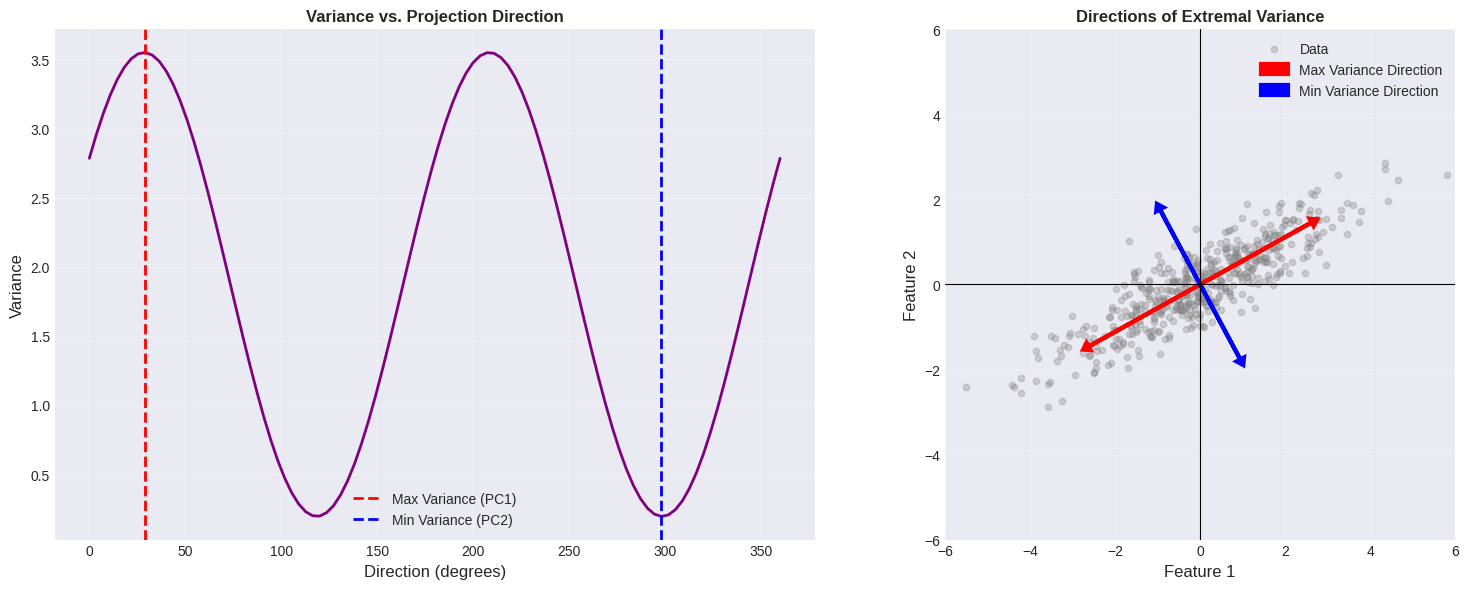


💡 The direction of maximum variance is exactly the first eigenvector!
   This is why PCA uses eigenvectors for dimensionality reduction.


In [ ]:
# Visualize variance as a function of direction
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Polar plot of variance
ax1 = axes[0]
ax1.plot(np.degrees(angles), variances, linewidth=2, color='purple')
ax1.axvline(np.degrees(max_angle), color='red', linestyle='--',
           linewidth=2, label=f'Max Variance (PC1)')
ax1.axvline(np.degrees(min_angle), color='blue', linestyle='--',
           linewidth=2, label=f'Min Variance (PC2)')
ax1.set_xlabel('Direction (degrees)', fontsize=12)
ax1.set_ylabel('Variance', fontsize=12)
ax1.set_title('Variance vs. Projection Direction', fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Show projections at max and min variance
ax2 = axes[1]

# Plot data
ax2.scatter(data_centered[:, 0], data_centered[:, 1],
           alpha=0.3, s=20, c='gray', label='Data')

# Max variance direction
max_dir = np.array([np.cos(max_angle), np.sin(max_angle)]) * 3
ax2.arrow(0, 0, max_dir[0], max_dir[1], head_width=0.2, head_length=0.15,
         fc='red', ec='red', linewidth=3, label='Max Variance Direction')
ax2.arrow(0, 0, -max_dir[0], -max_dir[1], head_width=0.2, head_length=0.15,
         fc='red', ec='red', linewidth=3)

# Min variance direction
min_dir = np.array([np.cos(min_angle), np.sin(min_angle)]) * 2
ax2.arrow(0, 0, min_dir[0], min_dir[1], head_width=0.2, head_length=0.15,
         fc='blue', ec='blue', linewidth=3, label='Min Variance Direction')
ax2.arrow(0, 0, -min_dir[0], -min_dir[1], head_width=0.2, head_length=0.15,
         fc='blue', ec='blue', linewidth=3)

ax2.set_xlim(-6, 6)
ax2.set_ylim(-6, 6)
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)
ax2.axhline(y=0, color='k', linewidth=0.8)
ax2.axvline(x=0, color='k', linewidth=0.8)
ax2.set_xlabel('Feature 1', fontsize=12)
ax2.set_ylabel('Feature 2', fontsize=12)
ax2.set_title('Directions of Extremal Variance', fontsize=12, fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()

print("\n💡 The direction of maximum variance is exactly the first eigenvector!")
print("   This is why PCA uses eigenvectors for dimensionality reduction.")

### Dimensionality Reduction via Variance Maximization

**PCA Algorithm (conceptual):**
1. Center the data (subtract mean)
2. Compute covariance matrix
3. Find eigenvectors (principal components)
4. Sort by eigenvalue (largest first)
5. Keep top $k$ eigenvectors
6. Project data onto these $k$ directions

**Result:** New $k$-dimensional representation that preserves maximum variance!

In [ ]:
# Demonstrate PCA manually
# We'll reduce from 2D to 1D

# Keep only first principal component
pc1 = eigenvectors_cov[:, 0]

# Project data onto PC1
data_1d = data_centered @ pc1

# Reconstruct in 2D (for visualization)
data_reconstructed = np.outer(data_1d, pc1)

print(f"Original data shape: {data_centered.shape}")
print(f"Reduced data shape: {data_1d.shape}")
print(f"\nFirst PC1 direction: {pc1}")
print(f"Variance preserved: {eigenvalues_cov[0] / eigenvalues_cov.sum() * 100:.1f}%")

Original data shape: (500, 2)
Reduced data shape: (500,)

First PC1 direction: [0.87858165 0.47759218]
Variance preserved: 94.8%


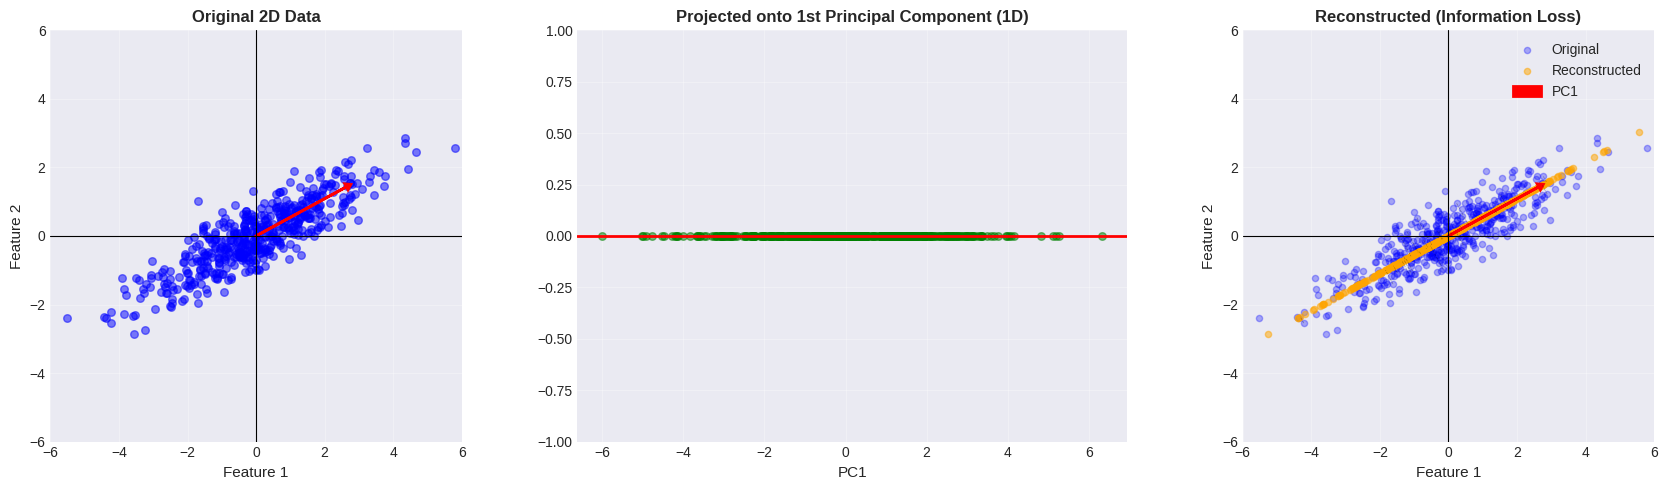


💡 PCA projects onto directions of maximum variance.
   We lose some information (perpendicular component), 
   but keep the most important patterns!


In [ ]:
# Visualize dimensionality reduction
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original 2D data
axes[0].scatter(data_centered[:, 0], data_centered[:, 1],
               alpha=0.5, s=30, c='blue')
axes[0].arrow(0, 0, pc1[0]*3, pc1[1]*3, head_width=0.2, head_length=0.15,
             fc='red', ec='red', linewidth=2)
axes[0].set_xlim(-6, 6)
axes[0].set_ylim(-6, 6)
axes[0].set_aspect('equal')
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=0, color='k', linewidth=0.8)
axes[0].axvline(x=0, color='k', linewidth=0.8)
axes[0].set_title('Original 2D Data', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Feature 1', fontsize=11)
axes[0].set_ylabel('Feature 2', fontsize=11)

# Projected onto PC1 (1D)
axes[1].scatter(data_1d, np.zeros_like(data_1d),
               alpha=0.5, s=30, c='green')
axes[1].axhline(y=0, color='red', linewidth=2)
axes[1].set_ylim(-1, 1)
axes[1].set_title('Projected onto 1st Principal Component (1D)',
                 fontsize=12, fontweight='bold')
axes[1].set_xlabel('PC1', fontsize=11)
axes[1].grid(True, alpha=0.3)

# Reconstructed back to 2D (shows what's lost)
axes[2].scatter(data_centered[:, 0], data_centered[:, 1],
               alpha=0.3, s=20, c='blue', label='Original')
axes[2].scatter(data_reconstructed[:, 0], data_reconstructed[:, 1],
               alpha=0.5, s=20, c='orange', label='Reconstructed')

# Draw lines showing reconstruction error
for i in range(0, len(data_centered), 20):  # Every 20th point
    axes[2].plot([data_centered[i, 0], data_reconstructed[i, 0]],
                [data_centered[i, 1], data_reconstructed[i, 1]],
                'k--', alpha=0.3, linewidth=0.5)

axes[2].arrow(0, 0, pc1[0]*3, pc1[1]*3, head_width=0.2, head_length=0.15,
             fc='red', ec='red', linewidth=2, label='PC1')
axes[2].set_xlim(-6, 6)
axes[2].set_ylim(-6, 6)
axes[2].set_aspect('equal')
axes[2].grid(True, alpha=0.3)
axes[2].axhline(y=0, color='k', linewidth=0.8)
axes[2].axvline(x=0, color='k', linewidth=0.8)
axes[2].set_title('Reconstructed (Information Loss)',
                 fontsize=12, fontweight='bold')
axes[2].set_xlabel('Feature 1', fontsize=11)
axes[2].set_ylabel('Feature 2', fontsize=11)
axes[2].legend()

plt.tight_layout()
plt.show()

print("\n💡 PCA projects onto directions of maximum variance.")
print("   We lose some information (perpendicular component), ")
print("   but keep the most important patterns!")

---

## 6. Matrix Determinant: Volume Intuition

### What Is the Determinant?

The **determinant** of a square matrix $\mathbf{A}$ is a single number that captures how the matrix **scales volumes**:

$$\det(\mathbf{A})$$

**Geometric interpretation:**
- $|\det(\mathbf{A})| > 1$: Matrix expands volumes
- $|\det(\mathbf{A})| < 1$: Matrix shrinks volumes  
- $\det(\mathbf{A}) = 0$: Matrix collapses dimensions (singular/not invertible)
- $\det(\mathbf{A}) < 0$: Matrix flips orientation

**For 2×2 matrix:**
$$\det\begin{pmatrix} a & b \\ c & d \end{pmatrix} = ad - bc$$

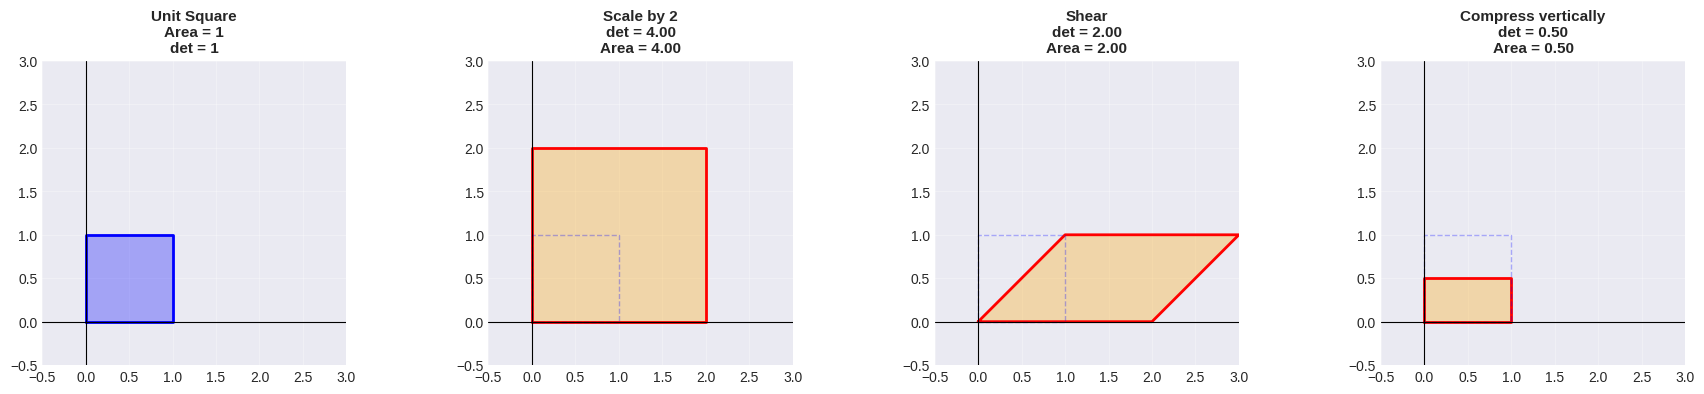


💡 Determinant = how much a matrix scales areas (2D) or volumes (3D+)!


In [ ]:
# Visualize determinant as area scaling
# Unit square
unit_square = np.array([[0, 1, 1, 0, 0],
                       [0, 0, 1, 1, 0]])

# Different transformation matrices
matrices = [
    (np.array([[2, 0], [0, 2]]), "Scale by 2"),
    (np.array([[2, 1], [0, 1]]), "Shear"),
    (np.array([[1, 0], [0, 0.5]]), "Compress vertically"),
]

fig, axes = plt.subplots(1, len(matrices) + 1, figsize=(18, 4))

# Original unit square
axes[0].fill(unit_square[0], unit_square[1], alpha=0.3, color='blue')
axes[0].plot(unit_square[0], unit_square[1], 'b-', linewidth=2)
axes[0].set_xlim(-0.5, 3)
axes[0].set_ylim(-0.5, 3)
axes[0].set_aspect('equal')
axes[0].grid(True, alpha=0.3)
axes[0].set_title('Unit Square\nArea = 1\ndet = 1', fontsize=11, fontweight='bold')
axes[0].axhline(y=0, color='k', linewidth=0.8)
axes[0].axvline(x=0, color='k', linewidth=0.8)

# Transformed squares
for idx, (matrix, name) in enumerate(matrices, 1):
    transformed = matrix @ unit_square
    det = np.linalg.det(matrix)

    axes[idx].fill(transformed[0], transformed[1], alpha=0.3, color='orange')
    axes[idx].plot(transformed[0], transformed[1], 'r-', linewidth=2)

    # Show original square faintly
    axes[idx].plot(unit_square[0], unit_square[1], 'b--',
                  linewidth=1, alpha=0.3, label='Original')

    axes[idx].set_xlim(-0.5, 3)
    axes[idx].set_ylim(-0.5, 3)
    axes[idx].set_aspect('equal')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_title(f'{name}\ndet = {det:.2f}\nArea = {det:.2f}',
                       fontsize=11, fontweight='bold')
    axes[idx].axhline(y=0, color='k', linewidth=0.8)
    axes[idx].axvline(x=0, color='k', linewidth=0.8)

plt.tight_layout()
plt.show()

print("\n💡 Determinant = how much a matrix scales areas (2D) or volumes (3D+)!")

### Connection to Eigenvalues

**Beautiful relationship:**
$$\det(\mathbf{A}) = \lambda_1 \times \lambda_2 \times \cdots \times \lambda_n$$

The determinant is the **product of all eigenvalues**!

**Why it matters for dimensionality reduction:**
- If $\det(\mathbf{C}) = 0$ for covariance matrix, data lies in a lower-dimensional subspace
- Small eigenvalues → near-zero determinant → data is nearly flat in some directions
- These flat directions can be safely removed!

In [ ]:
# Demonstrate eigenvalue-determinant relationship
A = np.array([[3, 1],
              [1, 3]])

det_A = np.linalg.det(A)
eigenvals, _ = np.linalg.eig(A)
product_eigenvals = np.prod(eigenvals)

print("Matrix A:")
print(A)
print(f"\nDeterminant: {det_A:.4f}")
print(f"Eigenvalues: {eigenvals}")
print(f"Product of eigenvalues: {product_eigenvals:.4f}")
print(f"\nAre they equal? {np.isclose(det_A, product_eigenvals)}")

# Example with singular matrix (det = 0)
B = np.array([[1, 2],
              [2, 4]])  # Second row is 2× first row

det_B = np.linalg.det(B)
eigenvals_B, _ = np.linalg.eig(B)

print("\n" + "="*50)
print("Singular Matrix B (rank deficient):")
print(B)
print(f"\nDeterminant: {det_B:.6f}  (≈ 0, not invertible!)")
print(f"Eigenvalues: {eigenvals_B}")
print("\n💡 One eigenvalue is 0 → determinant is 0 → matrix collapses a dimension!")

Matrix A:
[[3 1]
 [1 3]]

Determinant: 8.0000
Eigenvalues: [4. 2.]
Product of eigenvalues: 8.0000

Are they equal? True

Singular Matrix B (rank deficient):
[[1 2]
 [2 4]]

Determinant: 0.000000  (≈ 0, not invertible!)
Eigenvalues: [0. 5.]

💡 One eigenvalue is 0 → determinant is 0 → matrix collapses a dimension!


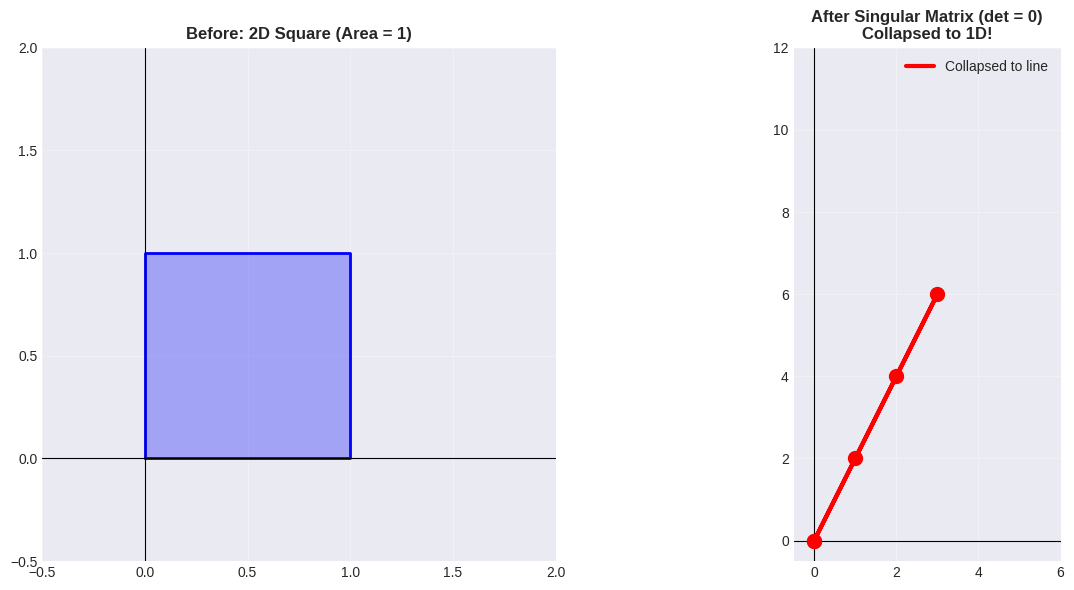


💡 When determinant = 0, the matrix squashes space into fewer dimensions.
   In ML: this means features are redundant (perfectly correlated)!


In [ ]:
# Visualize how singular matrix collapses space
unit_square = np.array([[0, 1, 1, 0, 0],
                       [0, 0, 1, 1, 0]])

collapsed = B @ unit_square

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Before transformation
axes[0].fill(unit_square[0], unit_square[1], alpha=0.3, color='blue')
axes[0].plot(unit_square[0], unit_square[1], 'b-', linewidth=2)
axes[0].set_xlim(-0.5, 2)
axes[0].set_ylim(-0.5, 2)
axes[0].set_aspect('equal')
axes[0].grid(True, alpha=0.3)
axes[0].set_title('Before: 2D Square (Area = 1)', fontsize=12, fontweight='bold')
axes[0].axhline(y=0, color='k', linewidth=0.8)
axes[0].axvline(x=0, color='k', linewidth=0.8)

# After transformation (collapsed to line)
axes[1].plot(collapsed[0], collapsed[1], 'r-', linewidth=3, label='Collapsed to line')
axes[1].scatter(collapsed[0], collapsed[1], c='red', s=100, zorder=5)
axes[1].set_xlim(-0.5, 6)
axes[1].set_ylim(-0.5, 12)
axes[1].set_aspect('equal')
axes[1].grid(True, alpha=0.3)
axes[1].set_title(f'After Singular Matrix (det = {det_B:.0f})\nCollapsed to 1D!',
                 fontsize=12, fontweight='bold')
axes[1].axhline(y=0, color='k', linewidth=0.8)
axes[1].axvline(x=0, color='k', linewidth=0.8)
axes[1].legend()

plt.tight_layout()
plt.show()

print("\n💡 When determinant = 0, the matrix squashes space into fewer dimensions.")
print("   In ML: this means features are redundant (perfectly correlated)!")

### Volume in Higher Dimensions

The same concept extends to 3D (volume) and beyond (hypervolume):

In [ ]:
# 3D example
# Unit cube vertices
unit_cube_vertices = np.array([
    [0, 1, 1, 0, 0, 1, 1, 0],
    [0, 0, 1, 1, 0, 0, 1, 1],
    [0, 0, 0, 0, 1, 1, 1, 1]
])

# Transformation matrix (3D)
transform_3d = np.array([
    [2, 0, 0],
    [0, 1.5, 0],
    [0, 0, 0.5]
])

transformed_cube = transform_3d @ unit_cube_vertices

det_3d = np.linalg.det(transform_3d)

print("3D Transformation Matrix:")
print(transform_3d)
print(f"\nDeterminant: {det_3d:.2f}")
print(f"Original unit cube volume: 1")
print(f"Transformed cube volume: {det_3d:.2f}")
print(f"\nScale factors: x={transform_3d[0,0]}, y={transform_3d[1,1]}, z={transform_3d[2,2]}")
print(f"Product of scale factors: {transform_3d[0,0] * transform_3d[1,1] * transform_3d[2,2]:.2f}")
print("\n💡 Determinant = product of how much each dimension is scaled!")

3D Transformation Matrix:
[[2.  0.  0. ]
 [0.  1.5 0. ]
 [0.  0.  0.5]]

Determinant: 1.50
Original unit cube volume: 1
Transformed cube volume: 1.50

Scale factors: x=2.0, y=1.5, z=0.5
Product of scale factors: 1.50

💡 Determinant = product of how much each dimension is scaled!


---

## Summary: Connecting All Concepts

Let's see how everything comes together for **dimensionality reduction**:

### The Complete Picture

1. **Data as matrices** (Section 1)
   - Each row = data point in n-dimensional space
   - Centering shifts origin to data's center

2. **Matrix multiplication** (Section 2)
   - Transforms data geometrically
   - $\mathbf{X}\mathbf{W}$ projects all points simultaneously

3. **Dot products & projections** (Section 3)
   - Projection = shadow of data onto a direction
   - Reduces dimensions but loses perpendicular information

4. **Eigenvectors** (Section 4)
   - Special directions that remain unchanged (only scaled)
   - Eigenvectors of covariance matrix = principal directions

5. **Variance maximization** (Section 5)
   - Keep directions with largest variance = most information
   - First eigenvector = direction of maximum variance
   - This is PCA!

6. **Determinants** (Section 6)
   - Measures volume scaling
   - Product of eigenvalues
   - Zero determinant → redundant dimensions

### How PCA Works (Now You Understand Why!)

```python
# 1. Center data
X_centered = X - X.mean(axis=0)

# 2. Compute covariance matrix  
C = (X_centered.T @ X_centered) / (n - 1)

# 3. Get eigenvectors (principal components)
eigenvalues, eigenvectors = np.linalg.eig(C)

# 4. Sort by eigenvalue (variance)
idx = eigenvalues.argsort()[::-1]
eigenvectors = eigenvectors[:, idx]

# 5. Project onto top k components
X_reduced = X_centered @ eigenvectors[:, :k]
```

**You now understand:**
- Why we center (to find variance directions from origin)
- Why we use eigenvectors (they maximize variance)
- Why we sort by eigenvalue (to keep most information)
- Why it's called projection (geometric shadow onto subspace)

### Next Steps

With these foundations, you're ready to:
- Implement PCA from scratch
- Understand other dimensionality reduction methods (t-SNE, UMAP)
- Comprehend neural network architectures (linear layers are matrix multiplications!)
- Grasp advanced ML techniques built on linear algebra

**Remember:**
- Variance = information (Lecture 1)
- Vectors = data points (Lecture 2)  
- Covariance = relationships (Lecture 3)
- **Linear algebra = the language that ties it all together!**

---

## Key Takeaways

- **Matrices organize data**: rows = samples, columns = features

- **Matrix multiplication = geometric transformation**: rotations, scalings, projections

- **Projections reduce dimensions**: trade information for simplicity

- **Eigenvectors are special directions**: unchanged by transformation, only scaled

- **Covariance eigenvectors = principal components**: directions of maximum variance

- **Variance maximization = information preservation**: PCA keeps what matters most

- **Determinants measure volume scaling**: zero determinant = redundant dimensions

- **Linear algebra is the foundation of ML**: from PCA to deep learning, it all builds on these concepts

---

## Further Exploration

Try these exercises to deepen your understanding:

1. **Implement PCA from scratch** on a real dataset (e.g., iris or MNIST)
2. **Visualize eigenvectors** of different covariance matrices
3. **Compare variance preserved** with different numbers of principal components
4. **Experiment with transformations**: create rotation, scaling, shear matrices and visualize their effects
5. **Explore rank**: what happens when data has redundant features?

---